# LF-NS on a toy problem

This notebook follows one likelihood-free nested sampling run from start to finish on a two-dimensional problem whose evidence and posterior are known exactly. It shows

1. the problem;
2. the evidence estimate and its error over the iterations;
3. the termination criterion;
4. what the run costs;
5. how the live points contract;
6. the posterior sample;
7. the same problem with a **noisy** likelihood, which is the case LF-NS was designed for.

The sampler works in the unit square: every prior is uniform there, and a model maps a point to physical parameters through the inverse prior CDF. Here the unit square *is* the parameter space.

To run: `uv sync` in the repository root, then `uv run jupyter lab`.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

import lfns
import notebook_style as style

style.apply()
TOTAL, DEAD, LIVE = style.BLUE, style.ORANGE, style.AQUA  # fixed colour per quantity throughout

## 1. The problem

The likelihood is a mixture of two Gaussian peaks, a broad one carrying 70% of the mass and a narrow one carrying 30%. Both lie well inside the unit square, so with a uniform prior

- the evidence is `Z = 1` (`ln Z = 0`), and
- the posterior is the mixture itself.

The peaks occupy well under 1% of the prior, so a sampler that draws from the prior would waste almost every likelihood evaluation.

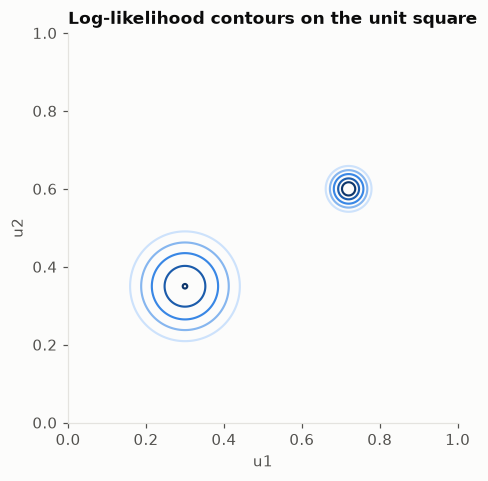

In [2]:
PEAKS = [  # weight, centre, standard deviation
    (0.7, np.array([0.30, 0.35]), 0.030),
    (0.3, np.array([0.72, 0.60]), 0.012),
]

def likelihood(points):
    # Vectorised over the rows of `points`.
    total = np.zeros(len(points))
    for weight, centre, width in PEAKS:
        squared_distance = ((points - centre) ** 2).sum(axis=1)
        total += weight * np.exp(-0.5 * squared_distance / width**2) / (2.0 * np.pi * width**2)
    return total

def log_likelihood(unit_point, seed):
    # Signature required by lfns: a point of the unit cube and a seed (unused here).
    return float(np.log(likelihood(unit_point[None, :])[0]))

axis = np.linspace(0.0, 1.0, 400)
mesh_x, mesh_y = np.meshgrid(axis, axis)
log_surface = np.log(likelihood(np.column_stack([mesh_x.ravel(), mesh_y.ravel()]))).reshape(mesh_x.shape)
CONTOUR_LEVELS = log_surface.max() - np.array([12.0, 8.0, 5.0, 2.5, 1.0])

fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.contour(mesh_x, mesh_y, log_surface, levels=CONTOUR_LEVELS, colors=style.BLUE_RAMP, linewidths=1.4)
ax.set_title("Log-likelihood contours on the unit square")
ax.set_xlabel("u1"); ax.set_ylabel("u2"); ax.set_aspect("equal"); ax.grid(False)

## 2. One run

`lfns.run` keeps `n_live` live points and replaces the `n_replaced` lowest of them in every iteration. Replacements are proposed uniformly from the support of a DP-GMM fitted to the surviving live points, and evaluated in parallel. The result does not depend on the number of threads: it is a function of the seed.

In [3]:
SETTINGS = dict(n_live=500, n_replaced=50, seed=0)

start = time.perf_counter()
result = lfns.run(log_likelihood, 2, **SETTINGS)
elapsed = time.perf_counter() - start
reports = result.reports()

print(f"stopped because:        {result.stop_reason}")
print(f"iterations:             {result.n_iterations}")
print(f"likelihood evaluations: {result.n_proposals}")
print(f"ln Z:                   {result.log_evidence:.3f} +- {result.relative_std:.3f}   (exact: 0)")
print(f"wall time:              {elapsed:.1f} s")

stopped because:        converged
iterations:             39
likelihood evaluations: 4460
ln Z:                   -0.128 +- 0.100   (exact: 0)
wall time:              2.0 s


### Evidence over the iterations

The evidence estimate has two parts:

- the **dead** part, integrated by the points removed so far, and
- the **live** part, the average likelihood of the current live points times the prior volume they still enclose.

Their sum is a valid estimate at *every* iteration, which is what allows LF-NS to stop early. Classical nested sampling uses only the dead part and must run until the live part is negligible.

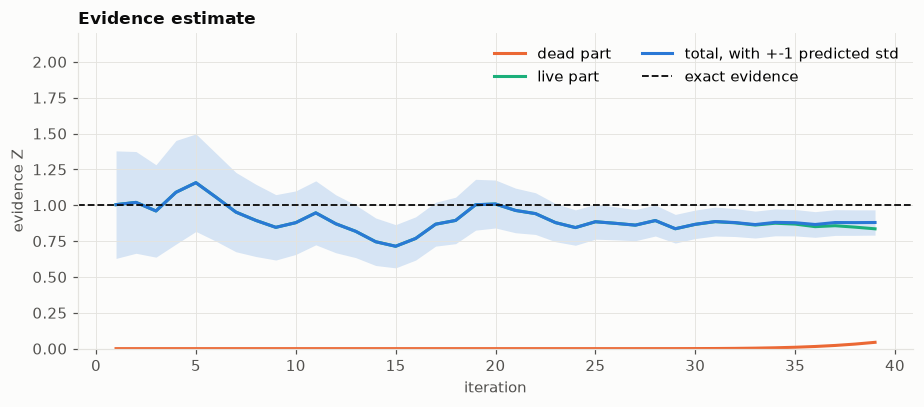

In [4]:
iteration = reports["iteration"]
total = np.exp(reports["log_evidence"])
band = total * reports["relative_std"]

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.fill_between(iteration, total - band, total + band, color=TOTAL, alpha=0.18, linewidth=0)
ax.plot(iteration, np.exp(reports["log_dead_evidence"]), color=DEAD, label="dead part")
ax.plot(iteration, np.exp(reports["log_live_evidence"]), color=LIVE, label="live part")
ax.plot(iteration, total, color=TOTAL, label="total, with +-1 predicted std")
ax.axhline(1.0, color=style.INK, lw=1.2, ls="--", label="exact evidence")
ax.set_ylim(0.0, 2.2); ax.set_xlabel("iteration"); ax.set_ylabel("evidence Z")
ax.set_title("Evidence estimate"); ax.legend(ncol=2, loc="upper right")
fig.tight_layout()

Early on the estimate is very uncertain: a few live points near a peak dominate the live average. As the live points climb the peaks the average stabilises and the band narrows.

Note where the run stops: the dead part is still only a few percent of the evidence. Almost all of it is carried by the live part. Classical nested sampling, which counts only the dead part, would have to continue several times longer to collect the same mass.

## 3. The termination criterion

The predicted variance of the estimate has two sources: the unknown prior volumes, and the Monte Carlo error of the live average. Removing the second gives a **floor**: the best standard deviation that running longer could achieve with this number of live points. The run stops when the gap between the current standard deviation and the floor, relative to `Z`, falls below the tolerance (default 0.01).

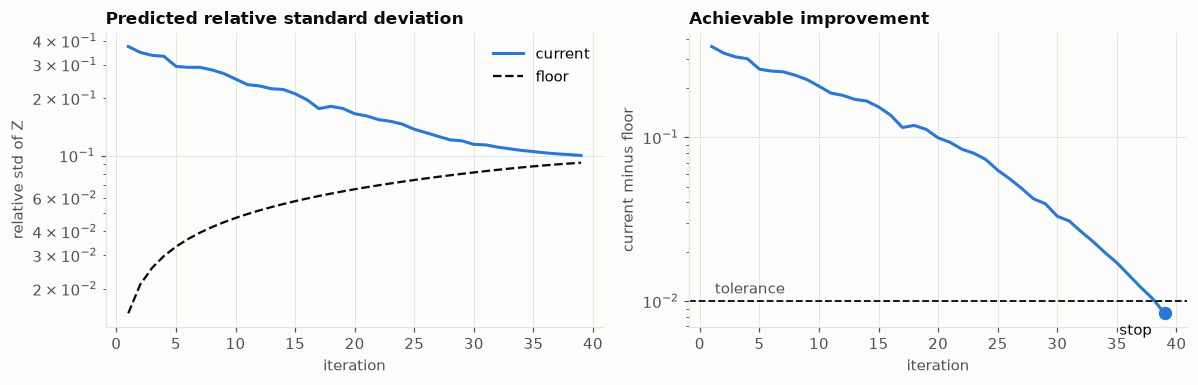

In [5]:
fig, (ax_std, ax_gap) = plt.subplots(1, 2, figsize=(11, 3.6))
ax_std.plot(iteration, reports["relative_std"], color=TOTAL, label="current")
ax_std.plot(iteration, reports["relative_floor_std"], color=style.INK, lw=1.5, ls="--", label="floor")
ax_std.set_yscale("log"); ax_std.set_xlabel("iteration"); ax_std.set_ylabel("relative std of Z")
ax_std.set_title("Predicted relative standard deviation"); ax_std.legend()

TOLERANCE = 0.01
ax_gap.plot(iteration, reports["achievable_improvement"], color=TOTAL)
ax_gap.axhline(TOLERANCE, color=style.INK, lw=1.2, ls="--")
ax_gap.annotate("tolerance", (iteration[0], TOLERANCE), textcoords="offset points", xytext=(2, 5), color=style.MUTED)
ax_gap.scatter(iteration[-1:], reports["achievable_improvement"][-1:], s=60, color=TOTAL, zorder=3)
ax_gap.annotate("stop", (iteration[-1], reports["achievable_improvement"][-1]), textcoords="offset points",
                xytext=(-8, -14), ha="right", color=style.INK)
ax_gap.set_yscale("log"); ax_gap.set_xlabel("iteration"); ax_gap.set_ylabel("current minus floor")
ax_gap.set_title("Achievable improvement")
fig.tight_layout()

The floor is set by the number of live points: more live points lower it. Iterations beyond the stopping point would shrink the gap further but cannot go below the floor, so they are not worth their cost.

## 4. What the run costs

The cost of an iteration is the number of likelihood evaluations needed to find the replacements, which is `n_replaced` divided by the acceptance rate. With a deterministic likelihood the acceptance rate is how much of the proposal region lies inside the true super-level set.

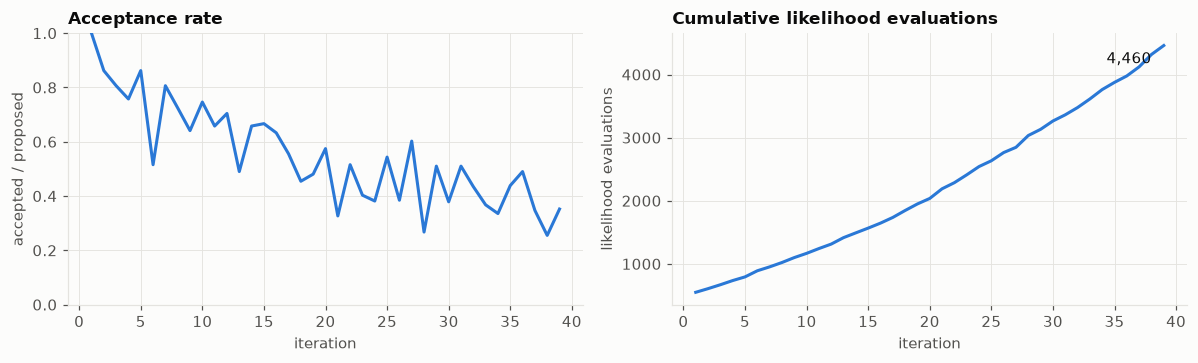

In [6]:
fig, (ax_rate, ax_cost) = plt.subplots(1, 2, figsize=(11, 3.4))
ax_rate.plot(iteration, reports["acceptance_rate"], color=TOTAL)
ax_rate.set_ylim(0.0, 1.0); ax_rate.set_xlabel("iteration"); ax_rate.set_ylabel("accepted / proposed")
ax_rate.set_title("Acceptance rate")

cumulative = SETTINGS["n_live"] + np.cumsum(reports["n_proposals"])
ax_cost.plot(iteration, cumulative, color=TOTAL)
ax_cost.set_xlabel("iteration"); ax_cost.set_ylabel("likelihood evaluations")
ax_cost.set_title("Cumulative likelihood evaluations")
ax_cost.annotate(f"{int(cumulative[-1]):,}", (iteration[-1], cumulative[-1]), textcoords="offset points",
                 xytext=(-8, -4), ha="right", va="top", color=style.INK)
fig.tight_layout()

## 5. How the live points contract

Because a run is a function of its seed, running again with the same seed and an iteration limit reproduces the earlier run up to that iteration. That gives snapshots of the live points without storing them.

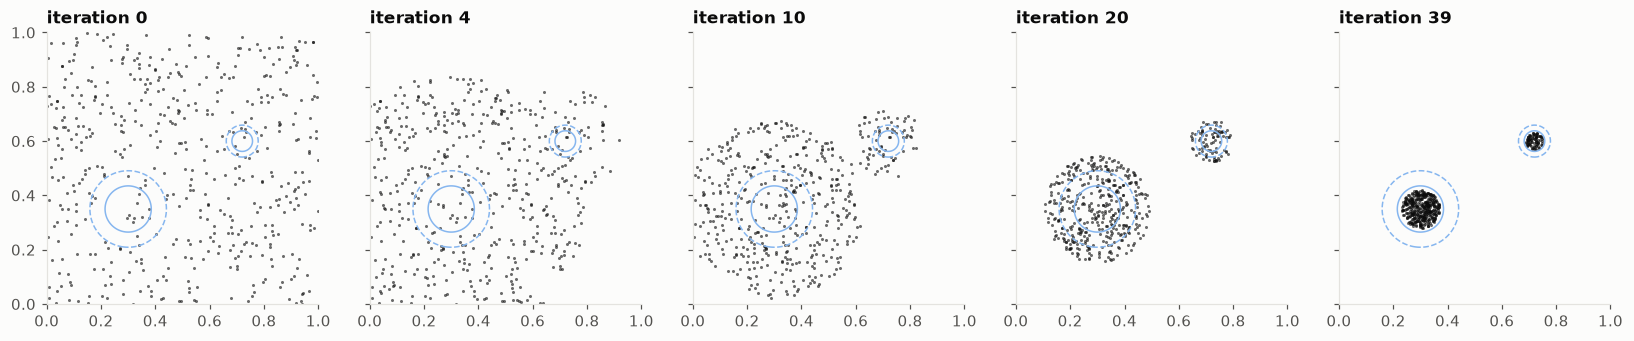

In [7]:
snapshot_iterations = [0, 4, 10, 20, result.n_iterations]
fig, axes = plt.subplots(1, len(snapshot_iterations), figsize=(15, 3.3), sharex=True, sharey=True)
for ax, limit in zip(axes, snapshot_iterations):
    snapshot = lfns.run(log_likelihood, 2, max_iterations=limit, **SETTINGS)
    points, _ = snapshot.live_points()
    ax.contour(mesh_x, mesh_y, log_surface, levels=CONTOUR_LEVELS[[0, 2]], colors=[style.BLUE_RAMP[1]], linewidths=1.0)
    ax.scatter(points[:, 0], points[:, 1], s=4, color=style.INK, alpha=0.6, linewidths=0)
    ax.set_title(f"iteration {limit}"); ax.set_aspect("equal"); ax.grid(False)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
fig.tight_layout()

Both peaks are found and kept. The DP-GMM proposal follows the two separate groups of live points, so no evaluations are wasted on the empty space between them.

## 6. The posterior

Every dead and live point carries a posterior weight: its likelihood times the prior volume it represents, divided by `Z`. The weighted points are a sample from the posterior. The effective sample size says how many equally weighted draws they are worth.

2450 weighted points, effective sample size 293
posterior mass of the broad peak: 0.715   (exact: 0.700)


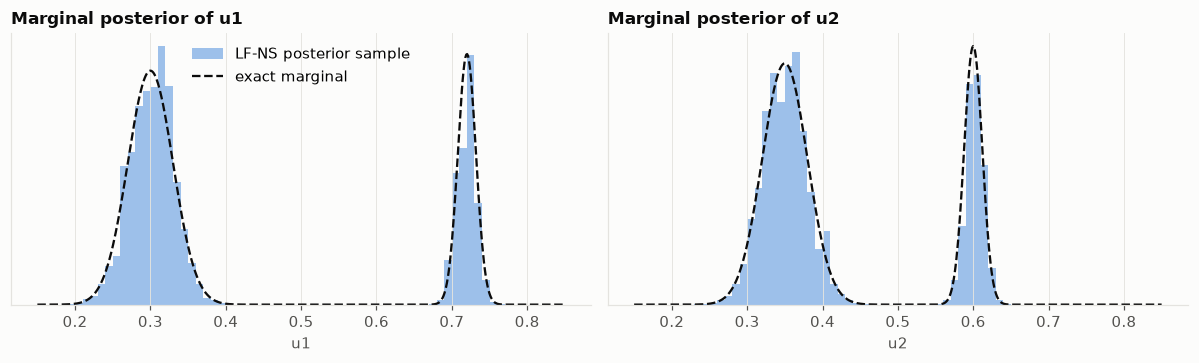

In [8]:
points, log_weights = result.posterior()
weights = np.exp(log_weights)
print(f"{len(points)} weighted points, effective sample size {result.effective_sample_size():.0f}")
in_broad_peak = points[:, 0] < 0.5
print(f"posterior mass of the broad peak: {weights[in_broad_peak].sum():.3f}   (exact: 0.700)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for dimension, ax in enumerate(axes):
    grid = np.linspace(0.15, 0.85, 600)
    exact = sum(w * stats.norm.pdf(grid, centre[dimension], width) for w, centre, width in PEAKS)
    ax.hist(points[:, dimension], bins=70, range=(0.15, 0.85), weights=weights, density=True,
            color=TOTAL, alpha=0.45, label="LF-NS posterior sample")
    ax.plot(grid, exact, color=style.INK, lw=1.5, ls="--", label="exact marginal")
    ax.set_xlabel(f"u{dimension + 1}"); ax.set_yticks([]); ax.set_title(f"Marginal posterior of u{dimension + 1}")
axes[0].legend()
fig.tight_layout()

## 7. A noisy likelihood

For a stochastic model the likelihood itself is not available, only an estimate of it, for example from a particle filter. LF-NS needs that estimate to be **unbiased** and nothing more.

We imitate this by multiplying the exact likelihood with log-normal noise of mean one. Each evaluation returns a different value for the same parameters. `SIGMA` is the standard deviation of the noise on the log scale; `SIGMA = 1` means a single estimate is routinely off by a factor of `e`.

In [9]:
SIGMA = 1.0

def noisy_log_likelihood(unit_point, seed):
    noise = np.random.default_rng(seed).normal()
    # exp(SIGMA * noise - SIGMA^2 / 2) has mean one, so the estimate is unbiased.
    return float(np.log(likelihood(unit_point[None, :])[0])) + SIGMA * noise - 0.5 * SIGMA**2

start = time.perf_counter()
noisy = lfns.run(noisy_log_likelihood, 2, **SETTINGS)
noisy_elapsed = time.perf_counter() - start
noisy_reports = noisy.reports()

print(f"{'':24}{'exact likelihood':>18}{'noisy likelihood':>18}")
print(f"{'ln Z (exact: 0)':24}{result.log_evidence:>18.3f}{noisy.log_evidence:>18.3f}")
print(f"{'predicted relative std':24}{result.relative_std:>18.3f}{noisy.relative_std:>18.3f}")
print(f"{'iterations':24}{result.n_iterations:>18}{noisy.n_iterations:>18}")
print(f"{'likelihood evaluations':24}{result.n_proposals:>18,}{noisy.n_proposals:>18,}")
print(f"{'wall time (s)':24}{elapsed:>18.1f}{noisy_elapsed:>18.1f}")

                          exact likelihood  noisy likelihood
ln Z (exact: 0)                     -0.128             0.015
predicted relative std               0.100             0.104
iterations                              39                46
likelihood evaluations               4,460             6,543
wall time (s)                          2.0               3.2


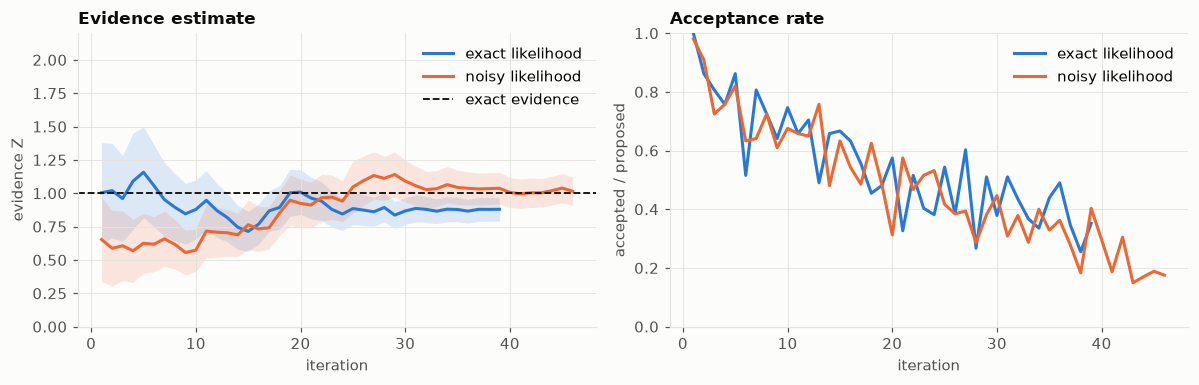

In [10]:
EXACT_RUN, NOISY_RUN = style.BLUE, style.ORANGE
fig, (ax_z, ax_rate) = plt.subplots(1, 2, figsize=(11, 3.6))
for run_reports, colour, label in [(reports, EXACT_RUN, "exact likelihood"), (noisy_reports, NOISY_RUN, "noisy likelihood")]:
    run_total = np.exp(run_reports["log_evidence"])
    run_band = run_total * run_reports["relative_std"]
    ax_z.fill_between(run_reports["iteration"], run_total - run_band, run_total + run_band, color=colour, alpha=0.15, linewidth=0)
    ax_z.plot(run_reports["iteration"], run_total, color=colour, label=label)
    ax_rate.plot(run_reports["iteration"], run_reports["acceptance_rate"], color=colour, label=label)
ax_z.axhline(1.0, color=style.INK, lw=1.2, ls="--", label="exact evidence")
ax_z.set_ylim(0.0, 2.2); ax_z.set_xlabel("iteration"); ax_z.set_ylabel("evidence Z"); ax_z.set_title("Evidence estimate")
ax_z.legend()
ax_rate.set_ylim(0.0, 1.0); ax_rate.set_xlabel("iteration"); ax_rate.set_ylabel("accepted / proposed")
ax_rate.set_title("Acceptance rate"); ax_rate.legend()
fig.tight_layout()

The noisy run still recovers the evidence, with a similar predicted error. It needs more iterations and more likelihood evaluations (see the table), and its acceptance rate keeps falling towards the end. The reason is that a proposal in the right place is accepted only if its likelihood *realization* exceeds the threshold, and late thresholds are set by lucky realizations. This is the cost the paper describes, and the reason early termination matters: the noisier the estimate (fewer particles in the filter), the more expensive every late iteration becomes.